# Phase 5 : Modélisation — Ridge vs Random Forest (Bike Sharing)

**Cible :** `cnt` — **Données :** `bike_sharing_final.csv` (produit par le notebook des phases 3-4)

Étapes :
1. Découpage **chronologique** 80 % train / 20 % test (aucun mélange aléatoire)
2. Deux pipelines de préparation adaptés à chaque modèle
3. Entraînement : **Ridge** (régression linéaire régularisée) et **Random Forest** (arbres de décision)
4. Évaluation : MAE, RMSE, R², RMSLE, MedAE, sur train **et** test
5. Visualisations
6. Sauvegarde des modèles entraînés

In [4]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------- Paramètres -------------------------
DATA_PATH    = "../bike_sharing_final.csv"   # adapter si besoin (ex. Colab : "/content/bike_sharing_final.csv")
TARGET       = "cnt"
TEST_SIZE    = 0.20
RANDOM_STATE = 42
MODELS_DIR   = Path("models")
FIG_DIR      = Path("figures")
# --------------------------------------------------------------
MODELS_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)

def save_show(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight"); plt.show()

## 1. Chargement et découpage chronologique 80 / 20

Le fichier est trié dans l'ordre du temps : on prend les **80 % premières lignes pour l'entraînement** et les **20 % dernières pour le test**.
Le modèle est donc évalué sur le futur, comme en situation réelle.

In [5]:
df = pd.read_csv(DATA_PATH)

expected = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
            "weathersit", "temp", "hum", "windspeed", "hr_sin", "hr_cos", TARGET]
missing = [c for c in expected if c not in df.columns]
assert not missing, f"Colonnes manquantes : {missing}"
assert df.isna().sum().sum() == 0, "Valeurs manquantes dans le fichier"

X = df.drop(columns=[TARGET])
y = df[TARGET]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, shuffle=True
)

print(f"Total : {len(df):,} lignes")
print(f"Train : {len(X_train):,} lignes ({len(X_train) / len(df):.0%})  | période : année {2011 + X_train['yr'].iloc[0]} mois {X_train['mnth'].iloc[0]}  ->  année {2011 + X_train['yr'].iloc[-1]} mois {X_train['mnth'].iloc[-1]}")
print(f"Test  : {len(X_test):,} lignes ({len(X_test) / len(df):.0%})  | période : année {2011 + X_test['yr'].iloc[0]} mois {X_test['mnth'].iloc[0]}  ->  année {2011 + X_test['yr'].iloc[-1]} mois {X_test['mnth'].iloc[-1]}")
print(f"\ncnt moyen  train : {y_train.mean():.1f}   test : {y_test.mean():.1f}")
print("Mois présents dans le test :", sorted(int(m) for m in X_test['mnth'].unique()))

Total : 17,379 lignes
Train : 13,903 lignes (80%)  | période : année 2012 mois 3  ->  année 2011 mois 10
Test  : 3,476 lignes (20%)  | période : année 2012 mois 9  ->  année 2011 mois 2

cnt moyen  train : 190.3   test : 186.1
Mois présents dans le test : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


## 2. Pipelines de préparation

Chaque modèle a sa propre préparation, intégrée dans un `Pipeline` (le même traitement est donc appliqué automatiquement au train, au test et en production) :

| | Ridge (linéaire) | Random Forest (arbres) |
|---|---|---|
| Variables numériques | **Standardisées** (`temp`, `hum`, `windspeed`, `hr_sin`, `hr_cos`, `mnth`, `yr`) | Telles quelles |
| Variables catégorielles | **One-hot** (`season`, `weathersit`, `weekday`) | Telles quelles |
| Binaires | Telles quelles (`holiday`, `workingday`) | Telles quelles |
| `hr` brut | **Exclu** (relation non linéaire, remplacé par `hr_sin`/`hr_cos`) | **Conservé** avec `hr_sin`, `hr_cos` |

Les arbres n'ont pas besoin de mise à l'échelle ; le Ridge, lui, y est sensible (pénalité L2).

In [17]:
# ---------- Ridge ----------
ridge_num = ["temp", "hum", "windspeed", "hr_sin", "hr_cos", "mnth", "yr"]
ridge_cat = ["season", "weathersit", "weekday"]
ridge_bin = ["holiday", "workingday"]

ridge_pre = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ridge_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ridge_cat),
        ("bin", "passthrough", ridge_bin),
    ],
    remainder="drop",
)
ridge_pipe = Pipeline([("prep", ridge_pre), ("model", Ridge(alpha=1.0, random_state=RANDOM_STATE , max_iter=1000))])

# ---------- Random Forest ----------
rf_features = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
               "weathersit", "temp", "hum", "windspeed", "hr_sin", "hr_cos"]
rf_pre = ColumnTransformer([("keep", "passthrough", rf_features)], remainder="drop")
rf_pipe = Pipeline([
    ("prep", rf_pre),
    ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                    n_jobs=1, random_state=RANDOM_STATE)),
])

# ---------- Référence : prédire toujours la moyenne du train ----------
dummy_pipe = Pipeline([("prep", rf_pre), ("model", DummyRegressor(strategy="mean"))])

models = {"Ridge": ridge_pipe, "Random Forest": rf_pipe}
print("Pipelines définis :", list(models))

Pipelines définis : ['Ridge', 'Random Forest']


## 3. Entraînement

In [18]:
fitted, fit_time = {}, {}
for name, pipe in models.items():
    t0 = time.time()
    fitted[name] = clone(pipe).fit(X_train, y_train)
    fit_time[name] = time.time() - t0
    print(f"{name:<22} entraîné en {fit_time[name]:.1f} s")

preds_train = {n: m.predict(X_train) for n, m in fitted.items()}
preds_test  = {n: m.predict(X_test)  for n, m in fitted.items()}

Ridge                  entraîné en 0.0 s
Random Forest          entraîné en 7.9 s


## 4. Évaluation

| Métrique | Lecture |
|---|---|
| **MAE** | Erreur moyenne en nombre de vélos par heure (facile à interpréter) |
| **RMSE** | Comme la MAE mais pénalise davantage les grosses erreurs (heures de pointe) |
| **R²** | Part de la variance de `cnt` expliquée (1 = parfait, 0 = pas mieux que la moyenne) |
| **RMSLE** | Erreur relative (en log) : peu sensible aux pics, pénalise les sous-prédictions. Les prédictions négatives sont ramenées à 0 |
| **MedAE** | Erreur médiane : robuste aux valeurs extrêmes |

In [19]:
def evaluate(y_true, y_pred):
    y_pred_pos = np.clip(y_pred, 0, None)   # pour RMSLE : pas de valeur négative
    return {
        "MAE":    mean_absolute_error(y_true, y_pred),
        "RMSE":   float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R²":     r2_score(y_true, y_pred),
        "RMSLE":  float(np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred_pos)))),
        "MedAE":  median_absolute_error(y_true, y_pred),
    }

metrics_test  = pd.DataFrame({n: evaluate(y_test,  p) for n, p in preds_test.items()}).T
metrics_train = pd.DataFrame({n: evaluate(y_train, p) for n, p in preds_train.items()}).T

print("=== TEST (20 % les plus récents) ===")
display(metrics_test.round(3))
print("\n=== TRAIN ===")
display(metrics_train.round(3))

gap = (metrics_test["RMSE"] / metrics_train["RMSE"]).round(2)
print("\nRatio RMSE test / train (≫ 1 = surapprentissage ou changement de régime) :")
print(gap.to_string())

=== TEST (20 % les plus récents) ===


,MAE,RMSE,R²,RMSLE,MedAE
Ridge,90.663,122.655,0.518,1.140,70.939
Random Forest,24.867,41.477,0.945,0.332,14.231



=== TRAIN ===


,MAE,RMSE,R²,RMSLE,MedAE
Ridge,93.743,128.669,0.503,1.164,71.887
Random Forest,13.048,22.838,0.984,0.203,7.077



Ratio RMSE test / train (≫ 1 = surapprentissage ou changement de régime) :
Ridge            0.95
Random Forest    1.82


## 5. Visualisations
### 5.1 Comparaison des métriques (test)

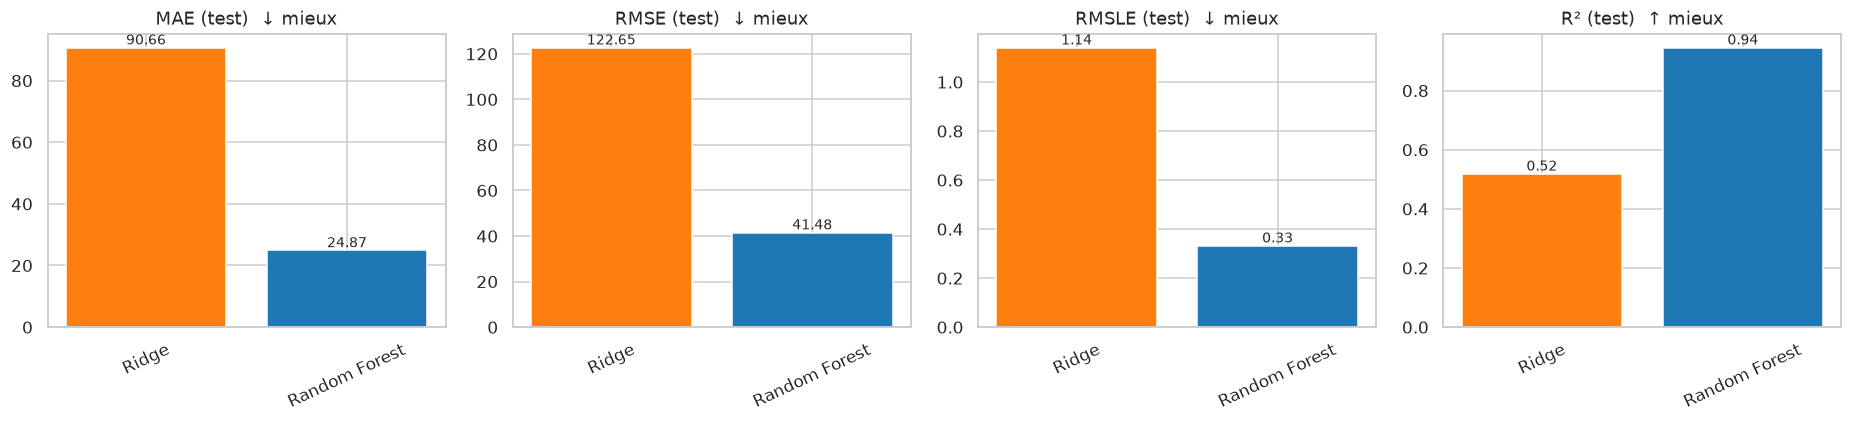

In [21]:
plot_names = list(metrics_test.index)
palette = {"Référence (moyenne)": "#9e9e9e", "Ridge": "tab:orange", "Random Forest": "tab:blue"}
colors = [palette[n] for n in plot_names]

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "RMSLE", "R²"]):
    vals = metrics_test.loc[plot_names, metric]
    bars = ax.bar(plot_names, vals, color=colors)
    ax.set_title(f"{metric} (test)" + ("  ↑ mieux" if metric == "R²" else "  ↓ mieux"))
    ax.tick_params(axis="x", rotation=25)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}", ha="center", va="bottom", fontsize=9)
save_show("01_comparaison_metriques")

### 5.2 Prédictions vs valeurs réelles et résidus

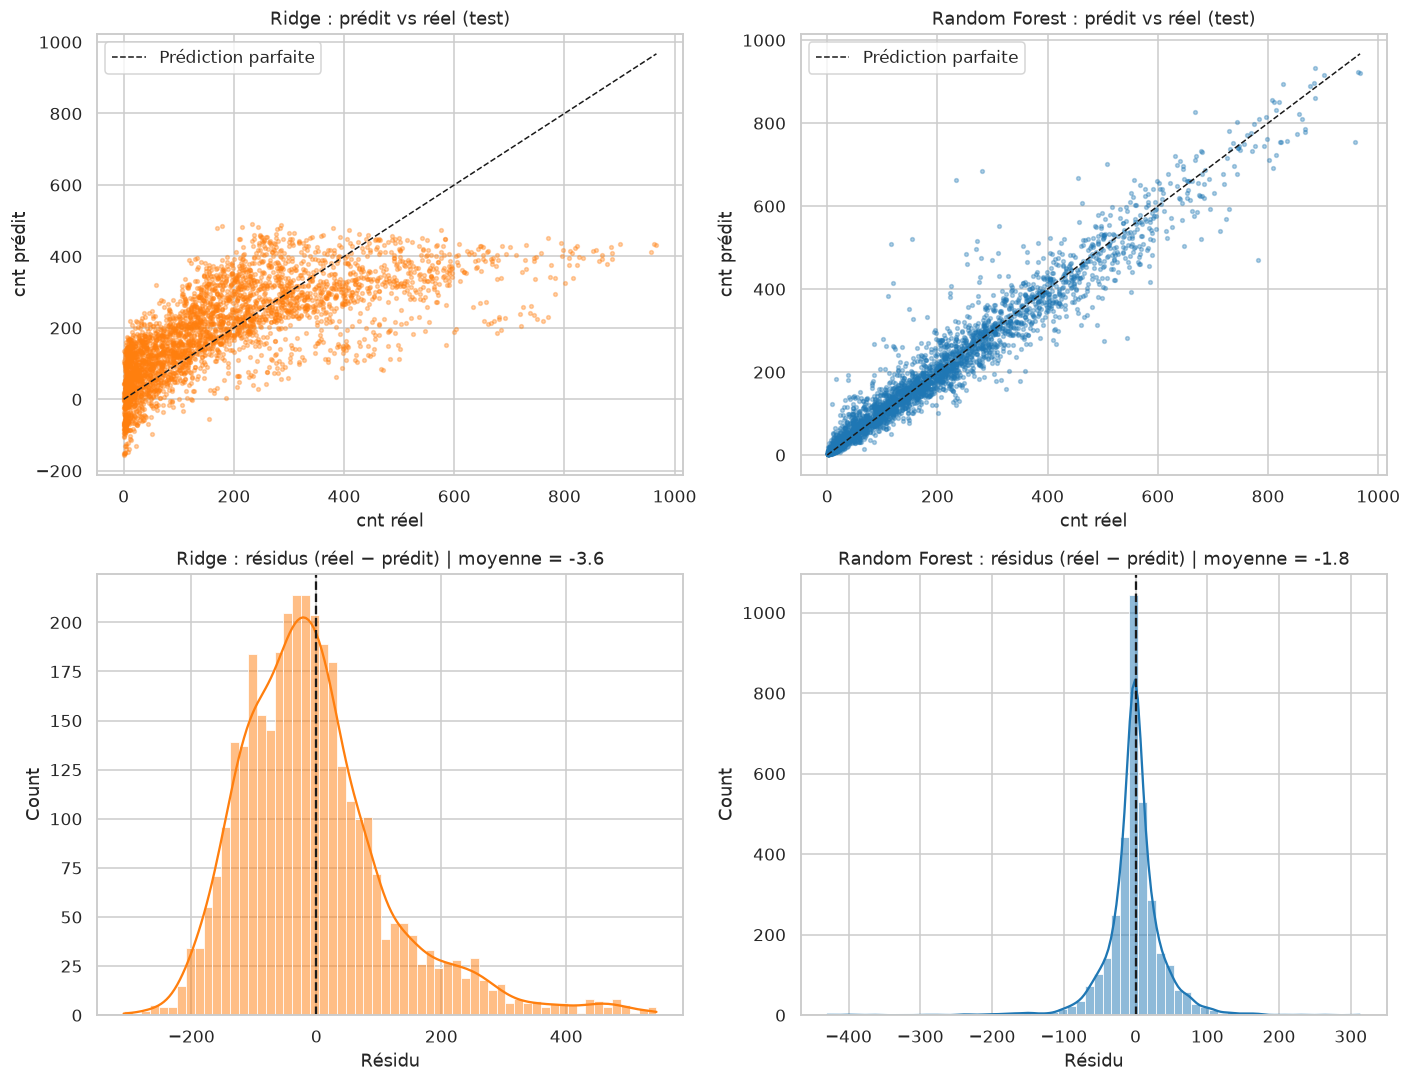

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
lim = max(y_test.max(), max(p.max() for p in (preds_test["Ridge"], preds_test["Random Forest"])))

for ax, (name, color) in zip(axes[0], [("Ridge", "tab:orange"), ("Random Forest", "tab:blue")]):
    ax.scatter(y_test, preds_test[name], s=6, alpha=0.35, color=color)
    ax.plot([0, lim], [0, lim], "k--", linewidth=1, label="Prédiction parfaite")
    ax.set(title=f"{name} : prédit vs réel (test)", xlabel="cnt réel", ylabel="cnt prédit")
    ax.legend()

for ax, (name, color) in zip(axes[1], [("Ridge", "tab:orange"), ("Random Forest", "tab:blue")]):
    res = y_test - preds_test[name]
    sns.histplot(res, bins=60, kde=True, ax=ax, color=color)
    ax.axvline(0, color="k", linestyle="--")
    ax.set(title=f"{name} : résidus (réel − prédit) | moyenne = {res.mean():.1f}", xlabel="Résidu")
save_show("02_predit_vs_reel_et_residus")

### 5.3 Série temporelle : les 300 dernières heures du test

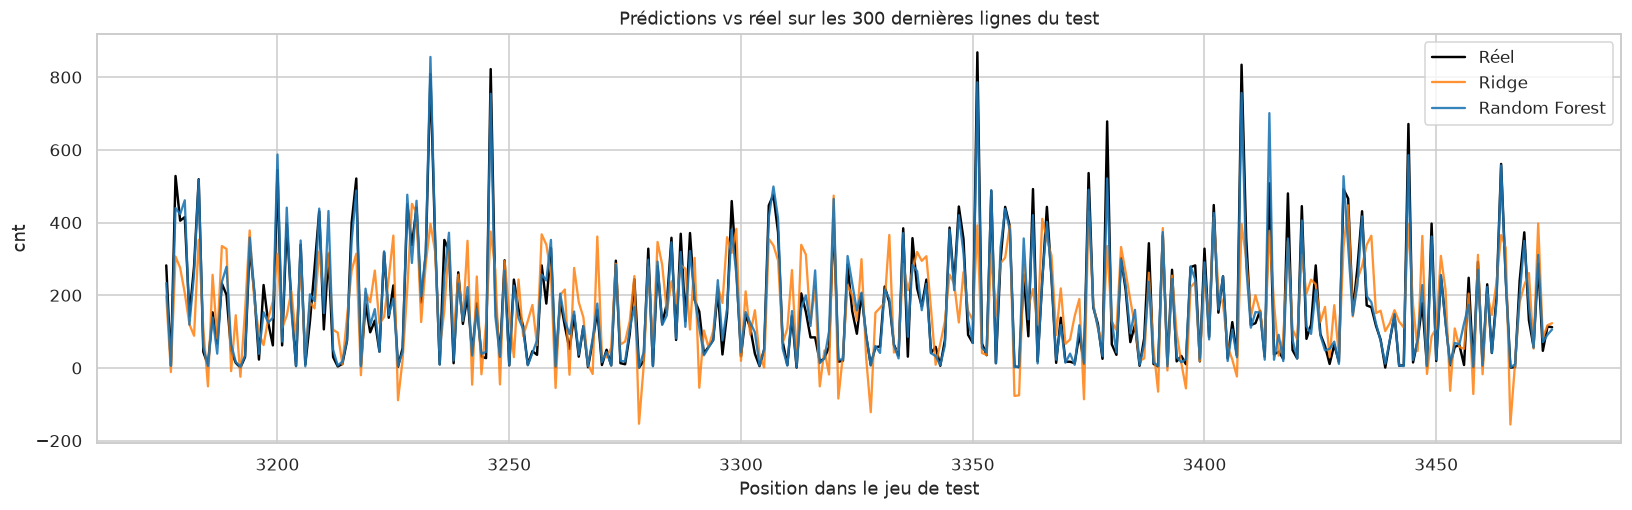

In [23]:
k = 300
idx = np.arange(len(y_test))[-k:]
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.plot(idx, y_test.values[-k:], color="black", linewidth=1.6, label="Réel")
ax.plot(idx, preds_test["Ridge"][-k:], color="tab:orange", alpha=0.85, label="Ridge")
ax.plot(idx, preds_test["Random Forest"][-k:], color="tab:blue", alpha=0.9, label="Random Forest")
ax.set(title=f"Prédictions vs réel sur les {k} dernières lignes du test", xlabel="Position dans le jeu de test", ylabel="cnt")
ax.legend()
save_show("03_serie_temporelle_test")

### 5.4 Où se trompent les modèles ? Erreur par heure et type de jour

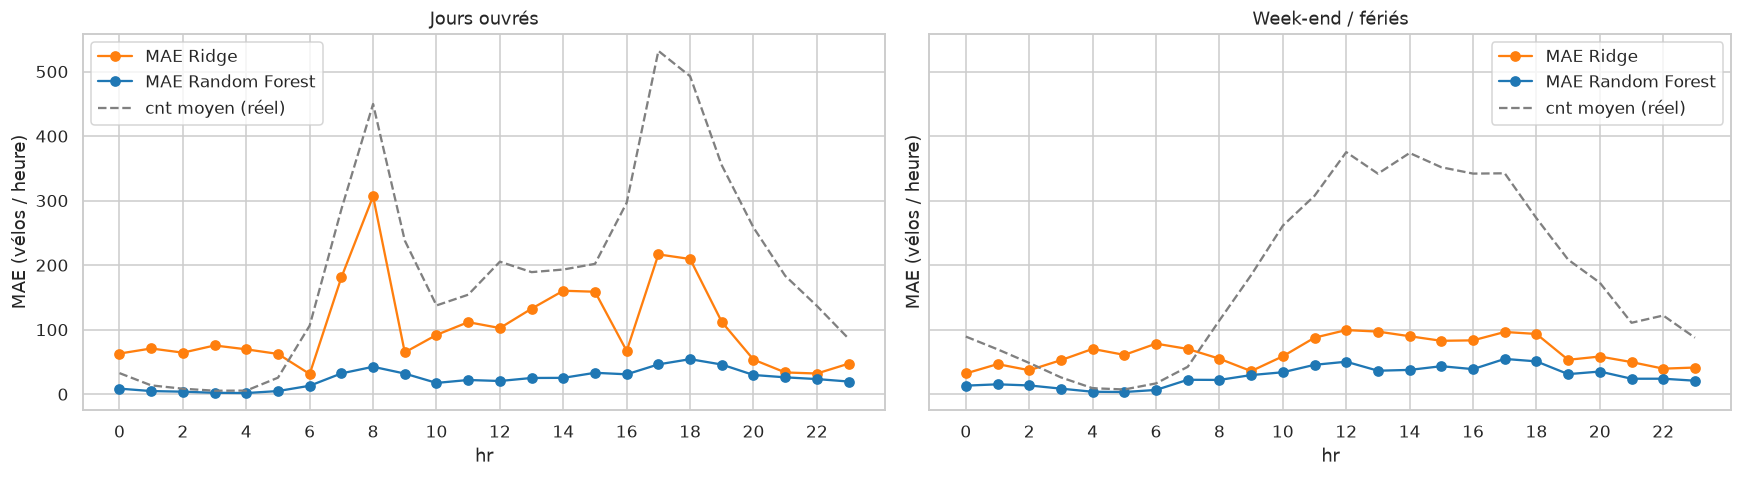

In [24]:
err = pd.DataFrame({
    "hr": X_test["hr"].values,
    "workingday": X_test["workingday"].values,
    "abs_err_ridge": np.abs(y_test.values - preds_test["Ridge"]),
    "abs_err_rf":    np.abs(y_test.values - preds_test["Random Forest"]),
    "cnt": y_test.values,
})

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, (wk, title) in zip(axes, [(1, "Jours ouvrés"), (0, "Week-end / fériés")]):
    g = err[err["workingday"] == wk].groupby("hr")[["abs_err_ridge", "abs_err_rf", "cnt"]].mean()
    ax.plot(g.index, g["abs_err_ridge"], marker="o", color="tab:orange", label="MAE Ridge")
    ax.plot(g.index, g["abs_err_rf"], marker="o", color="tab:blue", label="MAE Random Forest")
    ax.plot(g.index, g["cnt"], color="gray", linestyle="--", label="cnt moyen (réel)")
    ax.set(title=title, xlabel="hr", ylabel="MAE (vélos / heure)")
    ax.set_xticks(range(0, 24, 2)); ax.legend()
save_show("04_erreur_par_heure")

### 5.5 Courbe d'apprentissage

Les modèles sont ré-entraînés sur les **k % premières lignes du train** (ordre chronologique) puis évalués sur le même test.
Ce graphique remplace les courbes « epoch » qui n'existent pas pour ces modèles.

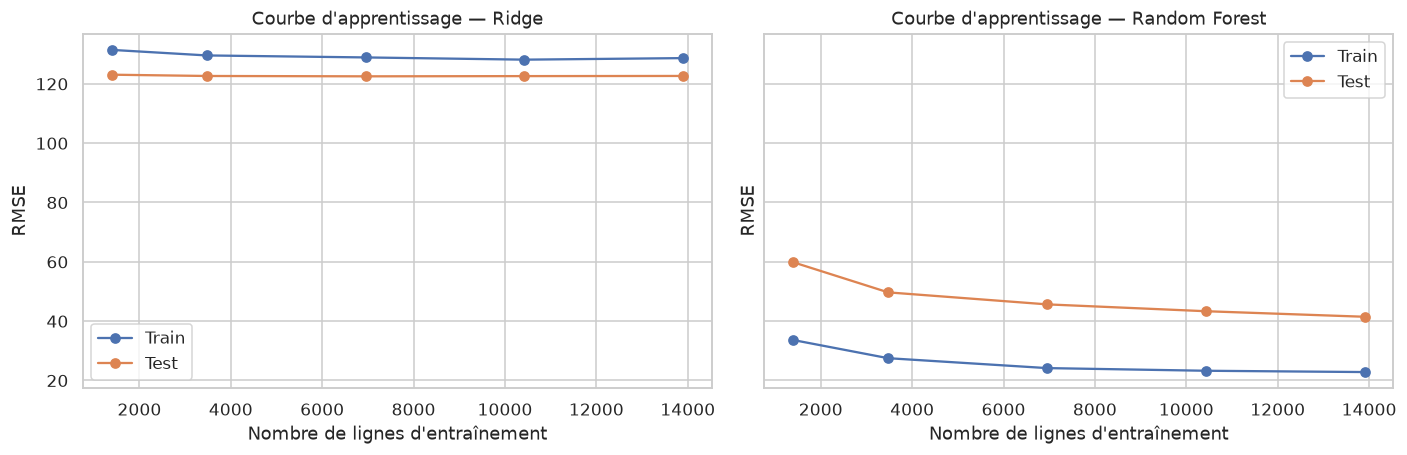

,modèle,fraction,n,RMSE train,RMSE test
0,Ridge,0.10,1390,131.44,123.08
1,Ridge,0.25,3475,129.57,122.65
2,Ridge,0.50,6951,128.90,122.53
3,Ridge,0.75,10427,128.15,122.60
4,Ridge,1.00,13903,128.67,122.65
5,Random Forest,0.10,1390,33.66,59.89
6,Random Forest,0.25,3475,27.51,49.70
7,Random Forest,0.50,6951,24.17,45.66
8,Random Forest,0.75,10427,23.27,43.35
9,Random Forest,1.00,13903,22.84,41.48


In [25]:
fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
rows = []
for name in ["Ridge", "Random Forest"]:
    for f in fractions:
        n = max(int(len(X_train) * f), 50)
        m = clone(models[name]).fit(X_train.iloc[:n], y_train.iloc[:n])
        rows.append({
            "modèle": name, "fraction": f, "n": n,
            "RMSE train": np.sqrt(mean_squared_error(y_train.iloc[:n], m.predict(X_train.iloc[:n]))),
            "RMSE test":  np.sqrt(mean_squared_error(y_test, m.predict(X_test))),
        })
lc = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, name in zip(axes, ["Ridge", "Random Forest"]):
    d = lc[lc["modèle"] == name]
    ax.plot(d["n"], d["RMSE train"], marker="o", label="Train")
    ax.plot(d["n"], d["RMSE test"], marker="o", label="Test")
    ax.set(title=f"Courbe d'apprentissage — {name}", xlabel="Nombre de lignes d'entraînement", ylabel="RMSE")
    ax.legend()
save_show("05_courbes_apprentissage")
lc.round(2)

### 5.6 Interprétation : coefficients du Ridge et importance des variables du Random Forest

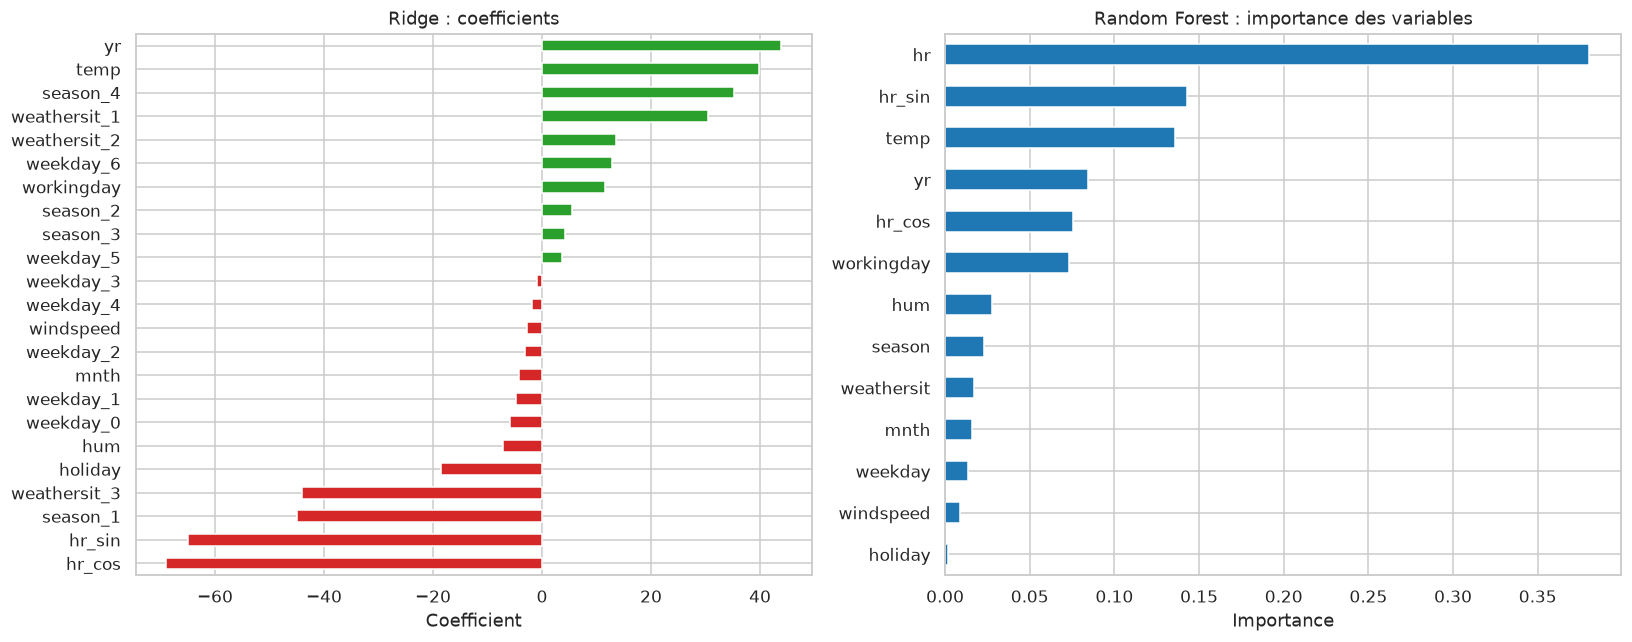

Top 5 variables (Random Forest) :
hr        0.380
hr_sin    0.143
temp      0.136
yr        0.084
hr_cos    0.075


In [26]:
# ----- Ridge : coefficients (variables standardisées => comparables entre elles) -----
ridge_names = [n.split("__", 1)[1] for n in fitted["Ridge"].named_steps["prep"].get_feature_names_out()]
coef = pd.Series(fitted["Ridge"].named_steps["model"].coef_, index=ridge_names).sort_values()

# ----- Random Forest : importance (impureté) -----
imp = pd.Series(fitted["Random Forest"].named_steps["model"].feature_importances_, index=rf_features).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
coef.plot(kind="barh", ax=axes[0], color=np.where(coef < 0, "tab:red", "tab:green"))
axes[0].set(title="Ridge : coefficients", xlabel="Coefficient")
imp.plot(kind="barh", ax=axes[1], color="tab:blue")
axes[1].set(title="Random Forest : importance des variables", xlabel="Importance")
save_show("06_interpretation")

print("Top 5 variables (Random Forest) :")
print(imp.sort_values(ascending=False).head(5).round(3).to_string())

## 6. Sauvegarde des modèles entraînés

On sauvegarde les **pipelines complets** (préparation + modèle) : en production, il suffit de charger le fichier et d'appeler `.predict()` sur un DataFrame brut avec les mêmes colonnes.

In [ ]:
joblib.dump(fitted["Ridge"],         MODELS_DIR / "ridge_pipeline.joblib", compress=3)
joblib.dump(fitted["Random Forest"], MODELS_DIR / "random_forest_pipeline.joblib", compress=3)  # compress=3 : fichier ~3x plus léger

# Métriques, prédictions et métadonnées
metrics_test.round(4).to_csv(MODELS_DIR / "metrics_test.csv")
metrics_train.round(4).to_csv(MODELS_DIR / "metrics_train.csv")
pd.DataFrame({"y_true": y_test.values,
              "pred_ridge": preds_test["Ridge"],
              "pred_random_forest": preds_test["Random Forest"]}).to_csv(MODELS_DIR / "predictions_test.csv", index=False)

meta = {
    "target": TARGET,
    "test_size": TEST_SIZE,
    "split": "chronologique (premières lignes = train, dernières = test)",
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "input_columns": list(X.columns),
    "ridge_params": fitted["Ridge"].named_steps["model"].get_params(),
    "random_forest_params": fitted["Random Forest"].named_steps["model"].get_params(),
    "metrics_test": metrics_test.round(4).to_dict(orient="index"),
}
(MODELS_DIR / "metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

for p in sorted(MODELS_DIR.iterdir()):
    print(f"{p.name:<32} {p.stat().st_size / 1024:>10,.1f} Ko")

In [ ]:
# Contrôle : on recharge les modèles et on vérifie qu'ils redonnent exactement les mêmes prédictions
ridge_loaded = joblib.load(MODELS_DIR / "ridge_pipeline.joblib")
rf_loaded    = joblib.load(MODELS_DIR / "random_forest_pipeline.joblib")

assert np.allclose(ridge_loaded.predict(X_test), preds_test["Ridge"])
assert np.allclose(rf_loaded.predict(X_test),    preds_test["Random Forest"])
print("Rechargement OK : prédictions identiques.")

## Récapitulatif et lecture des résultats

| Question | Où regarder |
|---|---|
| Quel modèle est le meilleur ? | Tableau « TEST » et graphique 5.1 |
| Y a-t-il du surapprentissage ? | Ratio RMSE test / train, courbes d'apprentissage (5.5) |
| Où sont les erreurs ? | Graphiques 5.3 et 5.4 (heures de pointe, jours ouvrés) |
| Quelles variables comptent ? | Graphique 5.6 |

**Pour réutiliser un modèle :**
```python
import joblib
model = joblib.load("models/random_forest_pipeline.joblib")
y_pred = model.predict(X_new)   # X_new : mêmes colonnes que bike_sharing_final.csv, sans cnt
```

**Suite (Phase 6) :** réglage des hyperparamètres avec `TimeSeriesSplit`, modèles de boosting (XGBoost, LightGBM), variables d'interaction (`workingday × hr`), lags.